# 2. DAILY RSI(2) MEAN REVERSION - IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK
## SYSTEMATIC TRADING APPROACH FOLLOWING ALPHACA FRAMEWORK

This notebook executes in-sample parameter sensitivity analysis on the **Alphaca RSI(2) Mean Reversion** strategy on daily bars.

### STRICT METHODOLOGICAL CONSTRAINT:
> **IN-SAMPLE DATA ONLY**: Out-of-sample data is strictly excluded from this notebook. All grids and sensitivity evaluations are performed on the in-sample portion (1999-12-21 through 2018-09-14).

### OBJECTIVES:
1. **Plateau vs. Cliff Validation**: Verify that the hypothesis-chosen parameters (`RSI=between 14 and 20, SMA=between 190 and 250`) reside on a wide, stable parameter plateau rather than an over-optimized isolated peak.
2. **Anti-Cliff Check**: Ensure moving one step away in any parameter direction does not cause performance to collapse (drop $\le 30\%$).

### STRATEGY PARAMETERS

In [42]:
VARIANT = "v1_sp500" # only base variants
STOP_LIMIT = 0.09

## 1. IMPORTS AND IN-SAMPLE DATA SETUP

In [43]:
import os
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR    = find_upwards('variants')                  # edge folder, any name
utils_path  = str(find_upwards('utils') / 'utils')      # research_development/utils
engine_path = str(EDGE_DIR)
engine_dir  = str(EDGE_DIR / 'rsi2_engine')

for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from robustness import grid_search, plateau_check, plot_grid
import rsi2_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), \
    f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
SMA_LEN    = cfg["params"]["sma_len"]
RSI_THR    = cfg["params"]["rsi_thr"]
EXIT_MODE  = cfg["params"]["exit_mode"]
SLIP_BPS   = cfg["params"]["slip_bps_per_side"]
RSI_VALUES = cfg["grid"]["rsi_values"]
SMA_VALUES = cfg["grid"]["sma_values"]

print("Imports complete.")
print(f"Variant: {cfg['id']} | {TICKER} | candidate RSI<{RSI_THR:g}, SMA({SMA_LEN}) | exit={EXIT_MODE} | {SLIP_BPS:g} bps/side")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")

df_raw = eng.load_data(TICKER, start=DATA_START)

common_start = eng.prepare(df_raw, sma_len=max(SMA_VALUES)).index[0]

df_full_prep = eng.prepare(df_raw, sma_len=SMA_LEN)
df_full_prep = df_full_prep[df_full_prep.index >= common_start]
is_end_date = df_full_prep.index[df_full_prep.index < OOS_START][-1]
n_is = int((df_full_prep.index <= is_end_date).sum())

print(f"Strict In-Sample Range: {df_full_prep.index.min().strftime('%Y-%m-%d')} to {is_end_date.strftime('%Y-%m-%d')}")
print(f"Total In-Sample Bars: {n_is:,}")

Imports complete.
Variant: RSI2.sp500.v1 | SP500 | candidate RSI<5, SMA(80) | exit=2green | 5 bps/side
Data source: csv_daily | swap: 2 bps/night
Strict In-Sample Range: 2007-07-27 to 2018-09-21
Total In-Sample Bars: 2,810


## 2. 2D PARAMETER GRID (RSI THRESHOLD X SMA PERIOD)

In [44]:
rsi_values = RSI_VALUES
sma_values = SMA_VALUES

# Precompute prepared data for each SMA length on the In-Sample slice only,
# all aligned to the exact same start and end dates.
is_dfs = {}
for sma in sma_values:
    prep = eng.prepare(df_raw, sma_len=sma)
    prep = prep[prep.index >= common_start]
    is_dfs[sma] = prep[prep.index <= is_end_date].copy()

assert len({(d.index[0], d.index[-1], len(d)) for d in is_dfs.values()}) == 1, \
    "All SMA series must use the same date window."

def evaluate(rsi, sma):
    d = is_dfs[sma]
    trades = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
    if len(trades) == 0:
        return (0.0, 0)
    p = trades['pnl'].values
    g, l = p[p > 0].sum(), -p[p < 0].sum()
    pf = float(g / l) if l > 0 else np.inf
    return (pf, int(len(trades)))

pf_grid, n_grid = grid_search(evaluate, rsi_values, sma_values)

print("=" * 70)
print("IN-SAMPLE PROFIT FACTOR GRID (RSI x SMA)")
print("=" * 70)
display(pf_grid.round(3))

print("\n" + "=" * 70)
print("IN-SAMPLE TRADE COUNT GRID (N)")
print("=" * 70)
display(n_grid.astype(int))

IN-SAMPLE PROFIT FACTOR GRID (RSI x SMA)


,20,50,80,110,140,170,200,230,260
5,16.862,4.374,2.547,2.707,2.804,1.815,1.847,1.824,1.922
10,1.125,2.417,1.859,2.108,1.929,1.607,1.543,1.589,1.569
15,2.053,1.705,1.632,1.778,1.733,1.535,1.537,1.551,1.614
20,1.552,1.799,1.328,1.517,1.615,1.365,1.277,1.314,1.366
25,1.394,1.458,1.344,1.320,1.441,1.333,1.266,1.300,1.366
30,1.232,1.175,1.086,1.120,1.151,1.213,1.155,1.169,1.168
35,1.197,1.120,1.050,1.094,1.094,1.150,1.100,1.113,1.116
40,1.284,1.204,1.096,1.084,1.055,1.143,1.141,1.152,1.152
45,1.117,1.085,1.032,1.029,0.933,1.010,0.940,1.030,0.981
50,1.085,1.079,1.016,1.012,0.927,1.010,0.941,1.029,0.954



IN-SAMPLE TRADE COUNT GRID (N)


,20,50,80,110,140,170,200,230,260
5,4,22,30,31,36,43,44,43,44
10,22,52,57,62,68,73,73,73,77
15,51,86,93,98,106,111,112,112,116
20,85,114,124,131,136,140,141,142,146
25,111,135,143,153,155,158,160,161,167
30,137,154,162,177,173,176,180,180,186
35,159,166,175,188,185,188,192,192,198
40,180,183,193,203,198,202,207,206,212
45,194,196,200,212,209,214,218,215,219
50,214,207,212,223,220,226,230,227,230


## 3. PARAMETER PLATEAU & ANTI-CLIFF VERIFICATION

PLATEAU DIAGNOSTIC RESULTS - Configured (5, 80):
  center_pf                : 2.547283214128336
  plateau                  : False
  worst_neighbor_drop_pct  : 27.0296094987193
  anticliff                : True
  passed                   : False
  pct_cells_pf_ok          : 0.41414141414141414
  best_cell                : (np.int64(5), np.int64(20))
  best_pf                  : 16.862087719051807
  edge_of_grid             : True
Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : FAILED
Anti-Cliff Condition (Worst neighbor drop <= 30%)        : PASSED
Overall Plateau Verdict                                   : FAILED


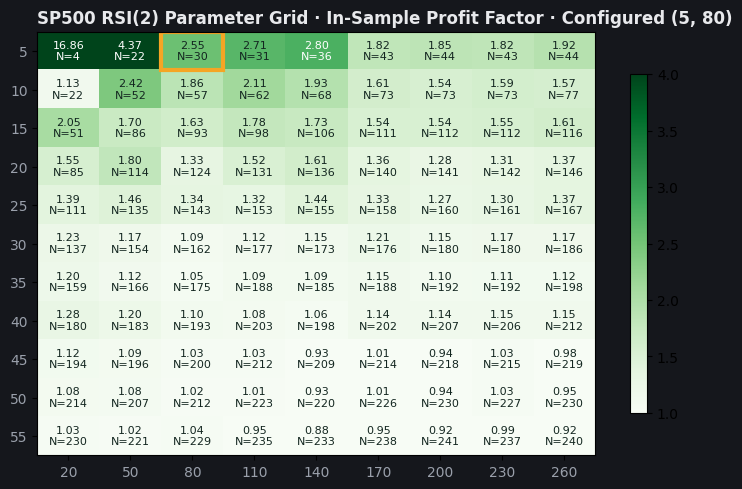

PLATEAU DIAGNOSTIC RESULTS - Baseline (15, 200):
  center_pf                : 1.5374714415607897
  plateau                  : False
  worst_neighbor_drop_pct  : 16.956932763098088
  anticliff                : True
  passed                   : False
  pct_cells_pf_ok          : 0.41414141414141414
  best_cell                : (np.int64(5), np.int64(20))
  best_pf                  : 16.862087719051807
  edge_of_grid             : False
Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : FAILED
Anti-Cliff Condition (Worst neighbor drop <= 30%)        : PASSED
Overall Plateau Verdict                                   : FAILED


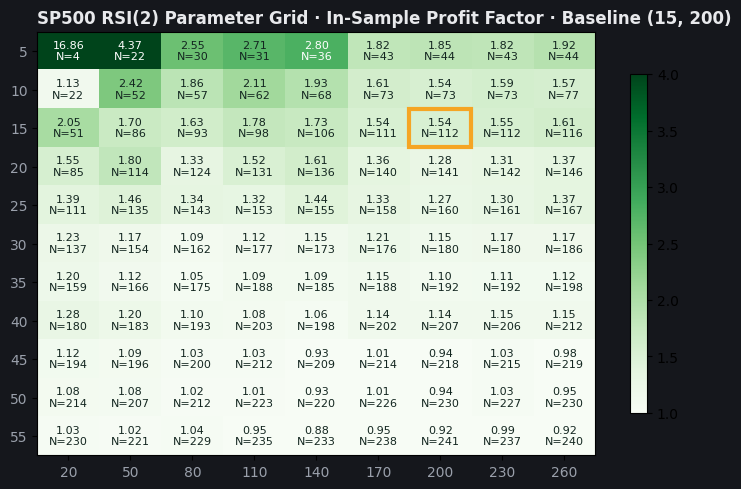

TEXT DUMP · 2D GRID (Two Green Candles · 5 bps) | * = configured, # = baseline

Profit Factor (rows = RSI threshold, cols = SMA length):
            20    50     80    110   140   170    200   230   260
RSI<\SMA                                                         
5         16.86  4.37  2.55*  2.71  2.80  1.82   1.85  1.82  1.92
10         1.13  2.42   1.86  2.11  1.93  1.61   1.54  1.59  1.57
15         2.05  1.70   1.63  1.78  1.73  1.54  1.54#  1.55  1.61
20         1.55  1.80   1.33  1.52  1.61  1.36   1.28  1.31  1.37
25         1.39  1.46   1.34  1.32  1.44  1.33   1.27  1.30  1.37
30         1.23  1.17   1.09  1.12  1.15  1.21   1.15  1.17  1.17
35         1.20  1.12   1.05  1.09  1.09  1.15   1.10  1.11  1.12
40         1.28  1.20   1.10  1.08  1.06  1.14   1.14  1.15  1.15
45         1.12  1.09   1.03  1.03  0.93  1.01   0.94  1.03  0.98
50         1.08  1.08   1.02  1.01  0.93  1.01   0.94  1.03  0.95
55         1.03  1.02   1.04  0.95  0.88  0.95   0.92  0.99  0.92

Trad

In [45]:
CHOSEN_POINTS = {
    f"Configured ({int(RSI_THR)}, {int(SMA_LEN)})": (int(RSI_THR), int(SMA_LEN)),
}
if (int(RSI_THR), int(SMA_LEN)) != (15, 200):
    CHOSEN_POINTS["Baseline (15, 200)"] = (15, 200)

checks = {}
for label, pt in CHOSEN_POINTS.items():
    check = plateau_check(pf_grid, n_grid, chosen=pt, pf_min=1.3, n_min=30, max_drop_pct=30.0)
    checks[label] = check

    print("=" * 70)
    print(f"PLATEAU DIAGNOSTIC RESULTS - {label}:")
    print("=" * 70)
    for k, v in check.items():
        print(f"  {k:<25}: {v}")
    print("=" * 70)
    print(f"Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : {'PASSED' if check['plateau'] else 'FAILED'}")
    print(f"Anti-Cliff Condition (Worst neighbor drop <= 30%)        : {'PASSED' if check['anticliff'] else 'FAILED'}")
    print(f"Overall Plateau Verdict                                   : {'PASSED' if check['passed'] else 'FAILED'}")
    print("=" * 70)

    plot_grid(pf_grid, n_grid, chosen=pt,
                title=f"{TICKER} RSI(2) Parameter Grid · In-Sample Profit Factor · {label}",
                vmin=1.0, vmax=4.0)

def grid_to_text(df, marks=None, fmt="{:.2f}"):
    """Grid -> aligned text. marks = {(rsi, sma): '*'} appends a marker to that cell."""
    s = df.astype(float).apply(lambda col: col.map(fmt.format))
    for (r, c), m in (marks or {}).items():
        if r in s.index and c in s.columns:
            s.loc[r, c] = s.loc[r, c] + m
    s.index.name = "RSI<\\SMA"
    return s.to_string()

marks = {pt: ("*" if i == 0 else "#") for i, pt in enumerate(CHOSEN_POINTS.values())}
print("=" * 70)
print("TEXT DUMP · 2D GRID (Two Green Candles · 5 bps) | * = configured, # = baseline")
print("=" * 70)
print("\nProfit Factor (rows = RSI threshold, cols = SMA length):")
print(grid_to_text(pf_grid.replace(np.inf, np.nan), marks))
print("\nTrades (N):")
print(grid_to_text(n_grid, marks, fmt="{:.0f}"))


## 4. 4D MULTI-SCENARIO ROBUSTNESS (3 EXITS X 2 COST LEVELS = 6 GRIDS)

4D MULTI-SCENARIO GRID RESULTS
Total Parameter Combinations Tested : 594
Combinations with PF >= 1.3         : 33.7% (200 / 594)
Combinations with PF >= 1.0         : 68.5% (407 / 594)
Minimum Profit Factor Across Grids  : 0.57
Median Profit Factor Across Grids   : 1.13
Maximum Profit Factor Across Grids  : 16.86
Chosen Config PF (5, 80, 2G, 5bps): 2.547
Percentile of Chosen Configuration  : 96.6%


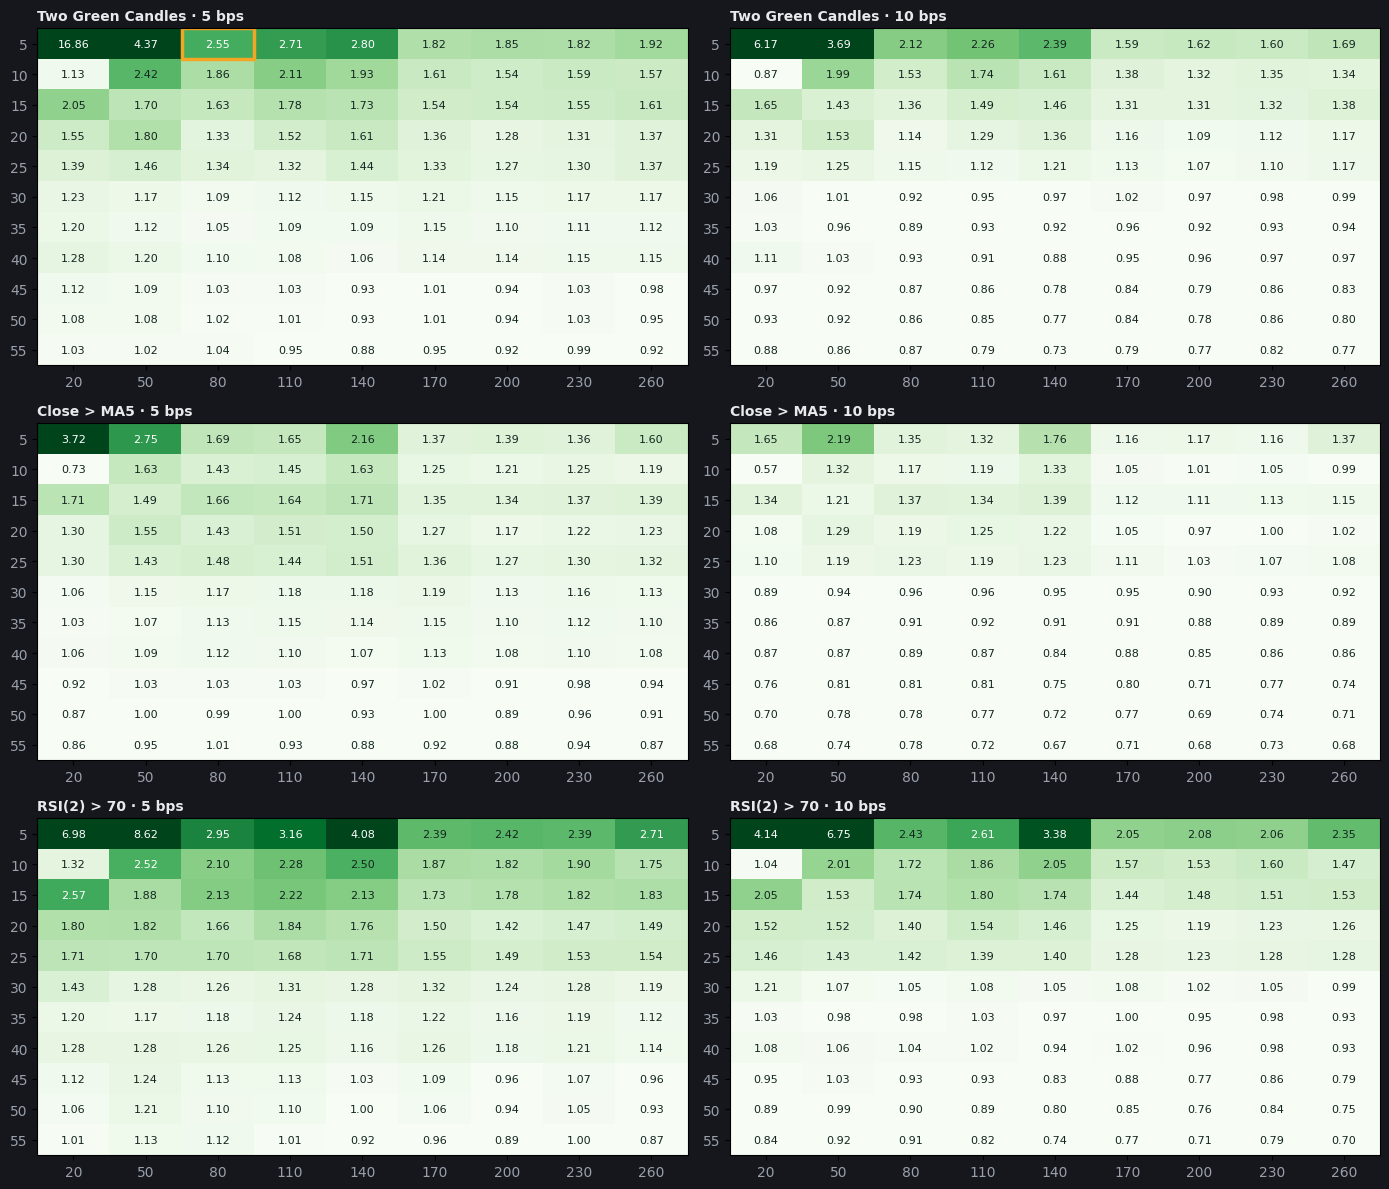

TEXT DUMP · 6 SCENARIOS
                           min  median    max  pct_ge_1_3  pct_ge_1_0
exit              cost                                               
Close > MA5       10 bps  0.57    0.93   2.19       12.12       42.42
                  5 bps   0.73    1.15   3.72       34.34       76.77
RSI(2) > 70       10 bps  0.70    1.06   6.75       36.36       62.63
                  5 bps   0.87    1.28   8.62       48.48       90.91
Two Green Candles 10 bps  0.73    1.01   6.17       29.29       50.51
                  5 bps   0.88    1.17  16.86       41.41       87.88

----------------------------------------------------------------------
Two Green Candles · 5 bps · Profit Factor
            20    50     80    110   140   170   200   230   260
RSI<\SMA                                                        
5         16.86  4.37  2.55*  2.71  2.80  1.82  1.85  1.82  1.92
10         1.13  2.42   1.86  2.11  1.93  1.61  1.54  1.59  1.57
15         2.05  1.70   1.63  1.78  1.73  

In [46]:
exits = [('2green', 'Two Green Candles'), ('ma5', 'Close > MA5'), ('rsi70', 'RSI(2) > 70')]
costs = [(5.0, '5 bps'), (10.0, '10 bps')]

all_combos = []
grid_results = {}

for exit_code, exit_label in exits:
    for slip_val, slip_label in costs:
        grid_key = f"{exit_label} · {slip_label}"
        pf_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        n_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=int)
        
        for rsi in rsi_values:
            for sma in sma_values:
                d = is_dfs[sma]
                trades = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=exit_code, slip_bps_per_side=slip_val)
                if len(trades) > 0:
                    p = trades['pnl'].values
                    g, l = p[p > 0].sum(), -p[p < 0].sum()
                    pf = float(g / l) if l > 0 else np.inf
                else:
                    pf = 0.0
                n = len(trades)
                pf_sub.loc[rsi, sma] = pf
                n_sub.loc[rsi, sma] = n
                
                all_combos.append({
                    'exit': exit_label, 'cost': slip_label, 'rsi': rsi, 'sma': sma,
                    'pf': pf, 'n': n
                })
        grid_results[grid_key] = pf_sub

combos_df = pd.DataFrame(all_combos)
pfs = combos_df['pf'].values

pct_pf13 = (pfs >= 1.3).mean() * 100.0
pct_pf10 = (pfs >= 1.0).mean() * 100.0
min_pf = pfs.min()
med_pf = np.median(pfs)
max_pf = pfs.max()

chosen_pf = combos_df.loc[
    (combos_df['exit'] == 'Two Green Candles') &
    (combos_df['cost'] == '5 bps') &
    (combos_df['rsi'] == int(RSI_THR)) &
    (combos_df['sma'] == int(SMA_LEN)), 'pf'
].values[0]

percentile_chosen = (pfs < chosen_pf).mean() * 100.0

print("=" * 70)
print("4D MULTI-SCENARIO GRID RESULTS")
print("=" * 70)
print(f"Total Parameter Combinations Tested : {len(combos_df)}")
print(f"Combinations with PF >= 1.3         : {pct_pf13:.1f}% ({int((pfs >= 1.3).sum())} / {len(combos_df)})")
print(f"Combinations with PF >= 1.0         : {pct_pf10:.1f}% ({int((pfs >= 1.0).sum())} / {len(combos_df)})")
print(f"Minimum Profit Factor Across Grids  : {min_pf:.2f}")
print(f"Median Profit Factor Across Grids   : {med_pf:.2f}")
print(f"Maximum Profit Factor Across Grids  : {max_pf:.2f}")
print(f"Chosen Config PF ({int(RSI_THR)}, {int(SMA_LEN)}, 2G, 5bps): {chosen_pf:.3f}")
print(f"Percentile of Chosen Configuration  : {percentile_chosen:.1f}%")
print("=" * 70)

# Display Grid Comparisons by Exit and Cost
fig, axes = plt.subplots(3, 2, figsize=(14, 12), facecolor='#15171c')
for idx, (title, grid_df) in enumerate(grid_results.items()):
    r, c = idx // 2, idx % 2
    ax = axes[r, c]
    ax.set_facecolor('#1b1e26')
    im = ax.imshow(grid_df.values, cmap='Greens', vmin=1.0, vmax=3.5, aspect='auto')
    ax.set_xticks(range(len(sma_values)))
    ax.set_xticklabels(sma_values, color='#9aa0ab')
    ax.set_yticks(range(len(rsi_values)))
    ax.set_yticklabels(rsi_values, color='#9aa0ab')
    ax.set_title(title, color='#e8e9ec', fontweight='bold', fontsize=10, loc='left')
    for i in range(len(rsi_values)):
        for j in range(len(sma_values)):
            val = grid_df.iloc[i, j]
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', fontsize=8,
                    color='white' if val > 2.5 else '#132620')
    if "Two Green Candles" in title and "5 bps" in title:
        ia, ib = rsi_values.index(int(RSI_THR)), sma_values.index(int(SMA_LEN))
        ax.add_patch(plt.Rectangle((ib - 0.5, ia - 0.5), 1, 1, fill=False, ec='#f5a524', lw=2.5))

plt.tight_layout()
plt.show()

# ---- per-scenario summary ----
print("=" * 70)
print("TEXT DUMP · 6 SCENARIOS")
print("=" * 70)
summ = (combos_df.groupby(["exit", "cost"])["pf"]
        .agg(min="min", median="median", max="max",
             pct_ge_1_3=lambda x: (x >= 1.3).mean() * 100,
             pct_ge_1_0=lambda x: (x >= 1.0).mean() * 100)
        .round(2))
print(summ.to_string())

# ---- full grids per scenario (PF and N) | * = configured point, only in 2G · 5 bps ----
for grid_key, pf_df in grid_results.items():
    exit_label, cost_label = grid_key.split(" · ")
    marks4 = {}
    if exit_label == "Two Green Candles" and cost_label == "5 bps":
        marks4[(int(RSI_THR), int(SMA_LEN))] = "*"
    n_df = (combos_df[(combos_df["exit"] == exit_label) & (combos_df["cost"] == cost_label)]
            .pivot(index="rsi", columns="sma", values="n"))
    print("\n" + "-" * 70)
    print(f"{grid_key} · Profit Factor")
    print(grid_to_text(pf_df.replace(np.inf, np.nan), marks4))
    print(f"\n{grid_key} · Trades (N)")
    print(grid_to_text(n_df, marks4, fmt="{:.0f}"))

In [47]:
for label, (r, s) in CHOSEN_POINTS.items():
    pf_pt = combos_df.loc[
        (combos_df['exit'] == 'Two Green Candles') & (combos_df['cost'] == '5 bps') &
        (combos_df['rsi'] == r) & (combos_df['sma'] == s), 'pf'
    ].values[0]
    print(f"{label:<22}: PF = {pf_pt:.3f} | percentile among {len(combos_df)} combinations = {(pfs < pf_pt).mean()*100:.1f}%")


Configured (5, 80)    : PF = 2.547 | percentile among 594 combinations = 96.6%
Baseline (15, 200)    : PF = 1.537 | percentile among 594 combinations = 80.8%


## 4.5 INTERACTIVE 3D PROFIT FACTOR SURFACE GRAPH

In [48]:
import numpy as np
import plotly.graph_objects as go
from numpy.lib.stride_tricks import sliding_window_view

LIMIT      = STOP_LIMIT # hard drawdown limit -> same value as cell 4.5
LIMIT_PCT  = LIMIT * 100
STAGE_DAYS = 252         # same stage length as cell 4.5

# Which loss decides PASS/FAIL:
#   "stage"    = worst loss vs the balance at the START of any 252-day stage (limit NOT trailing, as in 4.5's stage panel)
#   "trailing" = max drawdown from the running peak (stricter: always >= the stage loss in magnitude)
GATE = "stage"

# ---- limit check on the FULL period (same gate as 4.5: ATR sizing, trailing max drawdown) ----
# The PF surface stays in-sample (that's what gets optimised); the limit applies to the account
# over any stretch of time, so drawdown and stage loss come from the complete data (full_dfs).

# --- the engine asserts that the SMA column matches sma_len, so build one FULL-period frame per SMA ---
# (same recipe as is_dfs, but applied to the complete raw data instead of the in-sample slice)
RAW_FULL = df_raw
full_dfs = {int(sma): eng.prepare(RAW_FULL, sma_len=int(sma)) for sma in sma_values}
print(f"Prepared {len(full_dfs)} full-period frames from df_raw "
      f"({RAW_FULL.index.min():%Y-%m-%d} -> {RAW_FULL.index.max():%Y-%m-%d})")
_ref = globals().get("df_full_prep")
if _ref is not None and int(SMA_LEN) in full_dfs:
    _f = full_dfs[int(SMA_LEN)]
    print(f"Check vs df_full_prep (SMA {int(SMA_LEN)}): {len(_f)} vs {len(_ref)} rows, "
          f"{_f.index.min():%Y-%m-%d} vs {_ref.index.min():%Y-%m-%d} start")

n_grids, dd_grids, st_grids = {}, {}, {}
for exit_code, exit_label in exits:
    for slip_val, slip_label in costs:
        key = f"{exit_label} · {slip_label}"
        n_sub  = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        dd_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        st_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        for rsi in rsi_values:
            for sma in sma_values:
                d_full = full_dfs[int(sma)]
                t = eng.run_rsi2_backtest(d_full, rsi_thr=rsi, sma_len=sma, exit_mode=exit_code,
                                          slip_bps_per_side=slip_val)
                n_sub.loc[rsi, sma] = len(t)
                if len(t) > 0:
                    ret = eng.daily_returns(d_full, t, sizing="atr").astype(float)
                    eq = (1.0 + ret).cumprod()
                    dd_sub.loc[rsi, sma] = 100.0 * float((eq / eq.cummax() - 1.0).min())
                    if len(ret) >= STAGE_DAYS:
                        w = sliding_window_view(ret.values, STAGE_DAYS)
                        st_sub.loc[rsi, sma] = 100.0 * float(np.cumprod(1 + w, axis=1).min() - 1.0)
        n_grids[key], dd_grids[key], st_grids[key] = n_sub, dd_sub, st_sub

# ---- interactive 3D surface, one button per scenario ----
colorscale = [[0.00, "#b5452f"], [0.25, "#e8a46a"], [0.50, "#f4e79a"],
              [0.75, "#8fd19e"], [1.00, "#2f7d55"]]
# floor map: margin to the limit in percentage points (red = breaches, amber = on the edge, green = safe)
margin_scale = [[0.00, "#b5452f"], [0.45, "#e8704f"], [0.50, "#f5a524"], [0.55, "#8fd19e"], [1.00, "#34d399"]]

keys = list(grid_results.keys())

# shared scales so every scenario is comparable
pf_all  = [grid_results[k].astype(float).replace(np.inf, np.nan) for k in keys]
def _gate(k):
    """Grid of the loss that decides PASS/FAIL (falls back to the trailing DD where a stage doesn't fit)."""
    dd_, st_ = dd_grids[k].astype(float), st_grids[k].astype(float)
    return st_.fillna(dd_) if GATE == "stage" else dd_

amax    = max(float(np.nanmax(np.abs(_gate(k).values + LIMIT_PCT))) for k in keys)
amax    = max(amax, 1.0)
z_floor = min(1.0, float(np.nanmin([np.nanmin(p.values) for p in pf_all]))) - 0.35
z_top   = float(np.nanmax([np.nanmax(p.values) for p in pf_all])) + 0.25

TPS = 6                                   # traces per scenario
fig = go.Figure()
titles = []

for i, key in enumerate(keys):
    pf = grid_results[key].astype(float).replace(np.inf, np.nan)
    dd = dd_grids[key].astype(float).reindex(index=pf.index, columns=pf.columns)
    st = st_grids[key].astype(float).reindex(index=pf.index, columns=pf.columns)
    n  = n_grids[key].astype(float).reindex(index=pf.index, columns=pf.columns)

    g      = _gate(key).reindex(index=pf.index, columns=pf.columns)   # the loss that decides PASS/FAIL
    margin = g + LIMIT_PCT                               # >0 passes, <0 breaches (percentage points)
    ok     = (g >= -LIMIT_PCT) & g.notna()
    bad    = (g <  -LIMIT_PCT) & g.notna()
    verdict = np.where(ok.values, "PASS", np.where(bad.values, "FAIL", "n/a"))

    n_ok, n_tot = int(ok.values.sum()), int(g.notna().values.sum())

    # 1) Profit Factor surface (in-sample)
    cd = np.dstack([n.values, dd.values, margin.values, st.values])
    fig.add_trace(go.Surface(
        x=list(pf.columns), y=list(pf.index), z=pf.values, customdata=cd, text=verdict,
        colorscale=colorscale, cmin=1.0, cmax=3.0,
        colorbar=dict(title="Profit<br>Factor (IS)", len=0.42, y=0.80, x=0.93, thickness=14),
        hovertemplate=("SMA %{x}<br>RSI < %{y}<br>PF (IS) %{z:.2f}"
                       "<br>Trades (full) %{customdata[0]:.0f}"
                       "<br>MaxDD (full) %{customdata[1]:.1f}%"
                       "<br>Worst stage loss %{customdata[3]:.1f}%"
                       f"<br>Limit -{LIMIT_PCT:.0f}%: " + "%{text} (%{customdata[2]:+.1f} pp)<extra></extra>"),
        visible=(i == 0)))

    # 2) floor map: where the drawdown limit holds (projected under the surface)
    fig.add_trace(go.Surface(
        x=list(pf.columns), y=list(pf.index), z=np.full(pf.shape, z_floor),
        surfacecolor=margin.values, customdata=cd, text=verdict,
        colorscale=margin_scale, cmin=-amax, cmax=amax, opacity=0.95,
        colorbar=dict(title=f"Margin to<br>-{LIMIT_PCT:.0f}% (pp)", len=0.42, y=0.30, x=0.93, thickness=14),
        lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0),
        hovertemplate=("FLOOR · SMA %{x} · RSI < %{y}"
                       "<br>MaxDD (full) %{customdata[1]:.1f}%"
                       "<br>Worst stage loss %{customdata[3]:.1f}%"
                       f"<br>Limit -{LIMIT_PCT:.0f}%: " + "%{text} (%{customdata[2]:+.1f} pp)<extra></extra>"),
        visible=(i == 0)))

    # 3) markers on the surface: pass / fail
    X, Y = np.meshgrid(list(pf.columns), list(pf.index))
    for mask, name, color, symbol in ((ok, "Passes limit (full period)", "#34d399", "diamond"),
                                      (bad, "Breaches limit (full period)", "#f87171", "x")):
        m = (mask.values & pf.notna().values)
        fig.add_trace(go.Scatter3d(
            x=X[m], y=Y[m], z=pf.values[m] + 0.04, mode="markers", name=name,
            marker=dict(size=4, color=color, symbol=symbol, line=dict(width=0)),
            hovertemplate=f"{name}<br>SMA %{{x}} · RSI < %{{y}}<extra></extra>",
            showlegend=True, legendgroup=name, visible=(i == 0)))

    # 4) drop lines from the surface to the floor for the cells that pass
    m = (ok.values & pf.notna().values)
    xs, ys, zs = [], [], []
    for xv, yv, zv in zip(X[m], Y[m], pf.values[m]):
        xs += [xv, xv, None]; ys += [yv, yv, None]; zs += [zv, z_floor, None]
    fig.add_trace(go.Scatter3d(
        x=xs, y=ys, z=zs, mode="lines", line=dict(color="rgba(52,211,153,0.35)", width=2),
        hoverinfo="skip", showlegend=False, visible=(i == 0)))

    # 5) chosen config, flagged with its own verdict
    c_rsi, c_sma = int(RSI_THR), int(SMA_LEN)
    c_dd = float(g.loc[c_rsi, c_sma]) if pd.notna(g.loc[c_rsi, c_sma]) else np.nan
    c_ok = (not np.isnan(c_dd)) and c_dd >= -LIMIT_PCT
    fig.add_trace(go.Scatter3d(
        x=[c_sma], y=[c_rsi], z=[float(pf.loc[c_rsi, c_sma]) + 0.08],
        mode="markers+text", text=[f"chosen {'✓' if c_ok else '✗'}"], textposition="top center",
        textfont=dict(color="#34d399" if c_ok else "#f87171", size=13),
        marker=dict(size=7, color="white", line=dict(color="#34d399" if c_ok else "#f87171", width=3)),
        showlegend=False,
        hovertemplate=f"Chosen: RSI < {c_rsi}, SMA {c_sma}<br>{GATE} loss {c_dd:.2f}% vs -{LIMIT_PCT:.0f}%<extra></extra>",
        visible=(i == 0)))

    titles.append(f"{cfg['id']} · PF in-sample · {n_ok}/{n_tot} cells keep full-period {GATE} loss within -{LIMIT_PCT:.0f}%")

# ~3 px of breathing room on each side of every button label (non-breaking spaces)
PAD = "\u00a0"
buttons = []
for i, key in enumerate(keys):
    vis = [False] * (TPS * len(keys))
    for j in range(TPS):
        vis[TPS * i + j] = True
    buttons.append(dict(label=f"{PAD}{key}{PAD}", method="update",
                        args=[{"visible": vis}, {"title.text": titles[i]}]))

fig.update_layout(
    template="plotly_dark", paper_bgcolor="#15171c", height=700,
    title=dict(text=titles[0], x=0.02),
    scene=dict(
        xaxis_title="SMA length", yaxis_title="RSI threshold", zaxis_title="Profit Factor",
        zaxis=dict(range=[z_floor, z_top]),
        aspectmode="manual", aspectratio=dict(x=1.5, y=1.0, z=0.8),
        camera=dict(eye=dict(x=1.6, y=1.6, z=0.9), center=dict(x=0, y=0, z=-0.1))),
    legend=dict(x=0.0, y=0.02, bgcolor="rgba(0,0,0,0)", font=dict(color="#9aa0ab", size=11)),
    updatemenus=[dict(
        type="buttons", direction="right", x=0.0, xanchor="left", y=1.12, yanchor="top", active=0,
        buttons=buttons, bgcolor="#9fb3c8", bordercolor="#4a5160", borderwidth=1,
        pad=dict(l=3, r=3, t=0, b=0),
        font=dict(color="#15171c", size=12))],
    annotations=[dict(
        text=(f"Height = in-sample Profit Factor. Floor map and markers = headroom vs the -{LIMIT_PCT:.0f}% limit "
              f"on the FULL period, ATR sizing, gate = {GATE} loss (green = passes, amber = edge, red = breaches)."),
        x=0.0, y=-0.02, xref="paper", yref="paper", showarrow=False, xanchor="left",
        font=dict(color="#9aa0ab", size=11))],
    margin=dict(l=0, r=0, t=90, b=30))

# ---- sanity check: the chosen config must match cell 4.5 in its own scenario ----
chk = []
for key in keys:
    d_ = dd_grids[key].astype(float).loc[int(RSI_THR), int(SMA_LEN)]
    s_ = st_grids[key].astype(float).loc[int(RSI_THR), int(SMA_LEN)]
    g_ = s_ if (GATE == "stage" and not np.isnan(s_)) else d_
    chk.append({"Scenario": key, "MaxDD (trailing)": f"{d_:.2f}%", "Worst stage loss": f"{s_:.2f}%",
                f"gate={GATE} vs -{LIMIT_PCT:.0f}%": "PASS" if g_ >= -LIMIT_PCT else "FAIL"})
print("Chosen config (RSI < %d, SMA %d) by scenario - the one matching your frozen EXIT_MODE / SLIP_BPS must equal cell 4.5:" % (int(RSI_THR), int(SMA_LEN)))
display(pd.DataFrame(chk).set_index("Scenario"))

fig.show()
fig.write_html(Path(RUN_DIR) / "02_pf_surface.html", include_plotlyjs="cdn")

Prepared 9 full-period frames from df_raw (2006-07-17 -> 2026-07-15)
Check vs df_full_prep (SMA 80): 4951 vs 4771 rows, 2006-11-06 vs 2007-07-27 start
Chosen config (RSI < 5, SMA 80) by scenario - the one matching your frozen EXIT_MODE / SLIP_BPS must equal cell 4.5:


,MaxDD (trailing),Worst stage loss,gate=stage vs -9%
Scenario,,,
Two Green Candles · 5 bps,-7.68%,-6.03%,PASS
Two Green Candles · 10 bps,-8.24%,-6.34%,PASS
Close > MA5 · 5 bps,-5.82%,-4.99%,PASS
Close > MA5 · 10 bps,-6.49%,-5.30%,PASS
RSI(2) > 70 · 5 bps,-4.44%,-3.82%,PASS
RSI(2) > 70 · 10 bps,-4.75%,-3.84%,PASS


## 5. CONCLUSION & OPTIMIZATION FINDINGS

In [49]:
print("=" * 70)
print("CONCLUSIONS (computed from notebook results)")
print("=" * 70)
for label, chk in checks.items():
    print(f"{label}: center PF {chk['center_pf']:.3f} | worst neighbor -{chk['worst_neighbor_drop_pct']:.1f}% | "
          f"plateau {'PASS' if chk['plateau'] else 'FAIL'} | anti-cliff {'PASS' if chk['anticliff'] else 'FAIL'} | "
          f"edge of grid: {chk['edge_of_grid']}")
print(f"4D: {pct_pf13:.1f}% of {len(combos_df)} combinations with PF >= 1.3 "
      f"({int((pfs >= 1.3).sum())}/{len(combos_df)}), {pct_pf10:.1f}% with PF >= 1.0, "
      f"min {min_pf:.2f}, median {med_pf:.2f}, max {max_pf:.2f}")


CONCLUSIONS (computed from notebook results)
Configured (5, 80): center PF 2.547 | worst neighbor -27.0% | plateau FAIL | anti-cliff PASS | edge of grid: True
Baseline (15, 200): center PF 1.537 | worst neighbor -17.0% | plateau FAIL | anti-cliff PASS | edge of grid: False
4D: 33.7% of 594 combinations with PF >= 1.3 (200/594), 68.5% with PF >= 1.0, min 0.57, median 1.13, max 16.86


## 6. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [50]:
pd.DataFrame(pf_grid).to_csv(RUN_DIR / "02_pf_grid.csv")
pd.DataFrame(n_grid).to_csv(RUN_DIR / "02_n_grid.csv")

save_json(cfg, "02_optimization.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params_tested": {"rsi_thr": RSI_THR, "sma_len": SMA_LEN, "exit_mode": EXIT_MODE},
    "is_end_date": str(is_end_date.date()),
    "n_is_bars": int(n_is),
    "plateau_checks": checks,
    "grid_4d": {
        "n_combinations": int(len(combos_df)),
        "pct_pf_ge_1_3": float(pct_pf13),
        "pct_pf_ge_1_0": float(pct_pf10),
        "min_pf": float(min_pf),
        "median_pf": float(med_pf),
        "max_pf": float(max_pf),
        "chosen_pf": float(chosen_pf),
        "chosen_percentile": float(percentile_chosen),
    },
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2/runs/v1_sp500/02_optimization.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2/runs/v1_sp500/02_optimization.json')

## 7. OPTIMIZATION PARITY

In [51]:
BASE_VARIANT = "base_nasdaq"   # base variant: yaml name without .yaml. In the base/ETF notebooks: None

# Robustness: variant vs base (IN-SAMPLE ONLY).
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)
    rb_all = eng.load_data(cb["instrument"]["ticker"], start=DATA_START, source="yahoo")

    # Same in-sample window as the variant
    base_common = eng.prepare(rb_all, sma_len=max(SMA_VALUES)).index[0]
    if base_common > common_start:
        print(f"WARNING: base data starts later ({base_common:%Y-%m-%d}) than the variant window "
              f"({common_start:%Y-%m-%d}). Grids cover slightly different periods.")
    start_b = max(common_start, base_common)

    is_dfs_b = {}
    for sma in sma_values:
        prep = eng.prepare(rb_all, sma_len=sma)
        is_dfs_b[sma] = prep[(prep.index >= start_b) & (prep.index <= is_end_date)].copy()

    def evaluate_base(rsi, sma):
        t = eng.run_rsi2_backtest(is_dfs_b[sma], rsi_thr=rsi, sma_len=sma, exit_mode=EXIT_MODE,
                                  slip_bps_per_side=SLIP_BPS, financing_bps_per_night=0.0)
        if len(t) == 0:
            return (0.0, 0)
        p = t["pnl"].values
        g, l = p[p > 0].sum(), -p[p < 0].sum()
        return (float(g / l) if l > 0 else np.inf, int(len(t)))

    pf_b, n_b = grid_search(evaluate_base, rsi_values, sma_values)

    pf_v = pf_grid.replace(np.inf, np.nan).astype(float)
    pf_bc = pf_b.replace(np.inf, np.nan).astype(float)

    # 1) Grid-level comparison
    print("=" * 70)
    print(f"ROBUSTNESS: VARIANT ({cfg['id']}) vs BASE ({cb['id']}) | IN-SAMPLE")
    print("=" * 70)
    print("PF ratio variant/base per cell (1.00 = identical):")
    display((pf_v / pf_bc).round(3))

    both = pd.concat([pf_v.stack(), pf_bc.stack()], axis=1, keys=["v", "b"]).dropna()
    print(f"\nGrid correlation (PF, {len(both)} cells): {both['v'].corr(both['b']):.3f}")
    print(f"Median PF  variant/base: {both['v'].median():.3f} / {both['b'].median():.3f}")
    print(f"Cells PF >= 1.3 variant/base: {(both['v'] >= 1.3).sum()} / {(both['b'] >= 1.3).sum()} of {len(both)}")
    print(f"Cells PF >= 1.0 variant/base: {(both['v'] >= 1.0).sum()} / {(both['b'] >= 1.0).sum()} of {len(both)}")

    # 2) Plateau / anti-cliff on both grids, same chosen points as section 3
    print("\n" + "-" * 70)
    print(f"{'point':<22}{'':<10}{'center PF':>10}{'worst nb drop':>15}{'plateau':>9}{'anti-cliff':>12}")
    for label, pt in CHOSEN_POINTS.items():
        for name, g, n in (("variant", pf_grid, n_grid), ("base", pf_b, n_b)):
            c = plateau_check(g, n, chosen=pt, pf_min=1.3, n_min=30, max_drop_pct=30.0)
            print(f"{label:<22}{name:<10}{c['center_pf']:>10.3f}{c['worst_neighbor_drop_pct']:>14.1f}%"
                  f"{'PASS' if c['plateau'] else 'FAIL':>9}{'PASS' if c['anticliff'] else 'FAIL':>12}")
else:
    print("BASE_VARIANT is None: nothing to compare.")

ROBUSTNESS: VARIANT (RSI2.sp500.v1) vs BASE (RSI2.nasdaq.base) | IN-SAMPLE
PF ratio variant/base per cell (1.00 = identical):


,20,50,80,110,140,170,200,230,260
5,5.620,2.416,0.942,1.109,1.359,0.762,1.068,0.908,1.008
10,0.400,1.239,0.939,1.410,1.314,1.052,1.009,0.995,0.862
15,0.636,0.593,0.722,1.130,1.101,0.940,0.941,0.968,0.884
20,0.641,0.735,0.801,1.104,1.115,0.892,0.815,0.842,0.848
25,1.014,1.022,0.971,1.052,1.115,0.986,0.913,0.940,0.967
30,0.822,0.896,0.861,0.962,0.940,0.991,0.864,0.848,0.838
35,0.963,0.890,0.917,0.990,0.984,1.023,0.917,0.895,0.893
40,0.955,0.974,0.916,0.956,0.909,0.968,0.908,0.885,0.890
45,0.780,0.924,0.889,0.948,0.838,0.915,0.802,0.850,0.810
50,0.800,0.986,0.909,0.975,0.865,0.956,0.858,0.906,0.839



Grid correlation (PF, 99 cells): 0.493
Median PF  variant/base: 1.175 / 1.345
Cells PF >= 1.3 variant/base: 41 / 53 of 99
Cells PF >= 1.0 variant/base: 87 / 99 of 99

----------------------------------------------------------------------
point                            center PF  worst nb drop  plateau  anti-cliff
Configured (5, 80)    variant        2.547          27.0%     FAIL        PASS
Configured (5, 80)    base           2.703          44.7%     FAIL        FAIL
Baseline (15, 200)    variant        1.537          17.0%     FAIL        PASS
Baseline (15, 200)    base           1.634           6.5%     PASS        PASS
